# Biofilm Biomass Quantification Pipeline
### Lincoln Memorial Rock Surface: Pre- vs. Post-Liquid Droplet Analysis
**Author / Collaborator:** Computer Vision & Image Processing Pipeline
**Dataset:** Sample 3 (S3) — Before (`S3 Before the dropimage.TIF`) & After (`after the drop.tiff`)

---

## 1. Research Problem & Motivation
In studying biofilm dynamics on historic rock substrates (such as at the Lincoln Memorial in Washington, DC), water droplets are introduced to observe whether the physical distribution and optical density of biofilm biomass shifts.

### Key Analytical Obstacles Addressed:
1. **Camera Shift / Geometric Misalignment:** Video and still capture between droplets causes sub-pixel translation, rotation, and scale variations.
2. **Subjective Threshold Selection:** In manual Fiji/ImageJ analysis, selecting threshold cutoffs (e.g., 0-48 vs 0-81) introduces operator bias.
3. **Spatial Heterogeneity:** Biofilm clusters are non-uniform across the stone face, requiring comparison between **Whole Image** and **Sub-Region (ROI)** measurements.

This automated pipeline provides end-to-end reproducible image registration, multi-method segmentation (Fiji reproduction, Otsu, Triangle, Adaptive), 8-tile ROI analysis, and spatial difference mapping.


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Configure Matplotlib styling
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

print("Environment initialized successfully!")
print(f"OpenCV version: {cv2.__version__}")
print(f"NumPy version:  {np.__version__}")
print(f"Pandas version: {pd.__version__}")


/home/obigvee/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-81pobx57 because there was an issue with the default path (/home/obigvee/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Environment initialized successfully!
OpenCV version: 5.0.0
NumPy version:  2.2.6
Pandas version: 2.3.3


---
## 2. Data Ingestion & Preprocessing
We load the raw TIFF images for Sample 3 (S3). 
- **Before Image:** Loaded in RGB mode, converted to standardized 8-bit luminance grayscale:
  $$L = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B$$
- **After Image:** Already stored in 8-bit grayscale mode.


In [2]:
before_path = 'S3 Before the dropimage.TIF'
after_path = 'after the drop.tiff'

# Load images
before_raw = np.array(Image.open(before_path))
after_raw = np.array(Image.open(after_path))

# Standardize to 8-bit grayscale
if before_raw.ndim == 3:
    before_gray = cv2.cvtColor(before_raw, cv2.COLOR_RGB2GRAY)
else:
    before_gray = before_raw

after_gray = after_raw

print(f"[Before Image] Shape: {before_gray.shape} | Min: {before_gray.min()}, Max: {before_gray.max()}, Mean: {before_gray.mean():.2f}, Std: {before_gray.std():.2f}")
print(f"[After Image]  Shape: {after_gray.shape} | Min: {after_gray.min()}, Max: {after_gray.max()}, Mean: {after_gray.mean():.2f}, Std: {after_gray.std():.2f}")


[Before Image] Shape: (284, 716) | Min: 0, Max: 255, Mean: 131.71, Std: 68.41
[After Image]  Shape: (286, 718) | Min: 0, Max: 252, Mean: 120.40, Std: 65.81


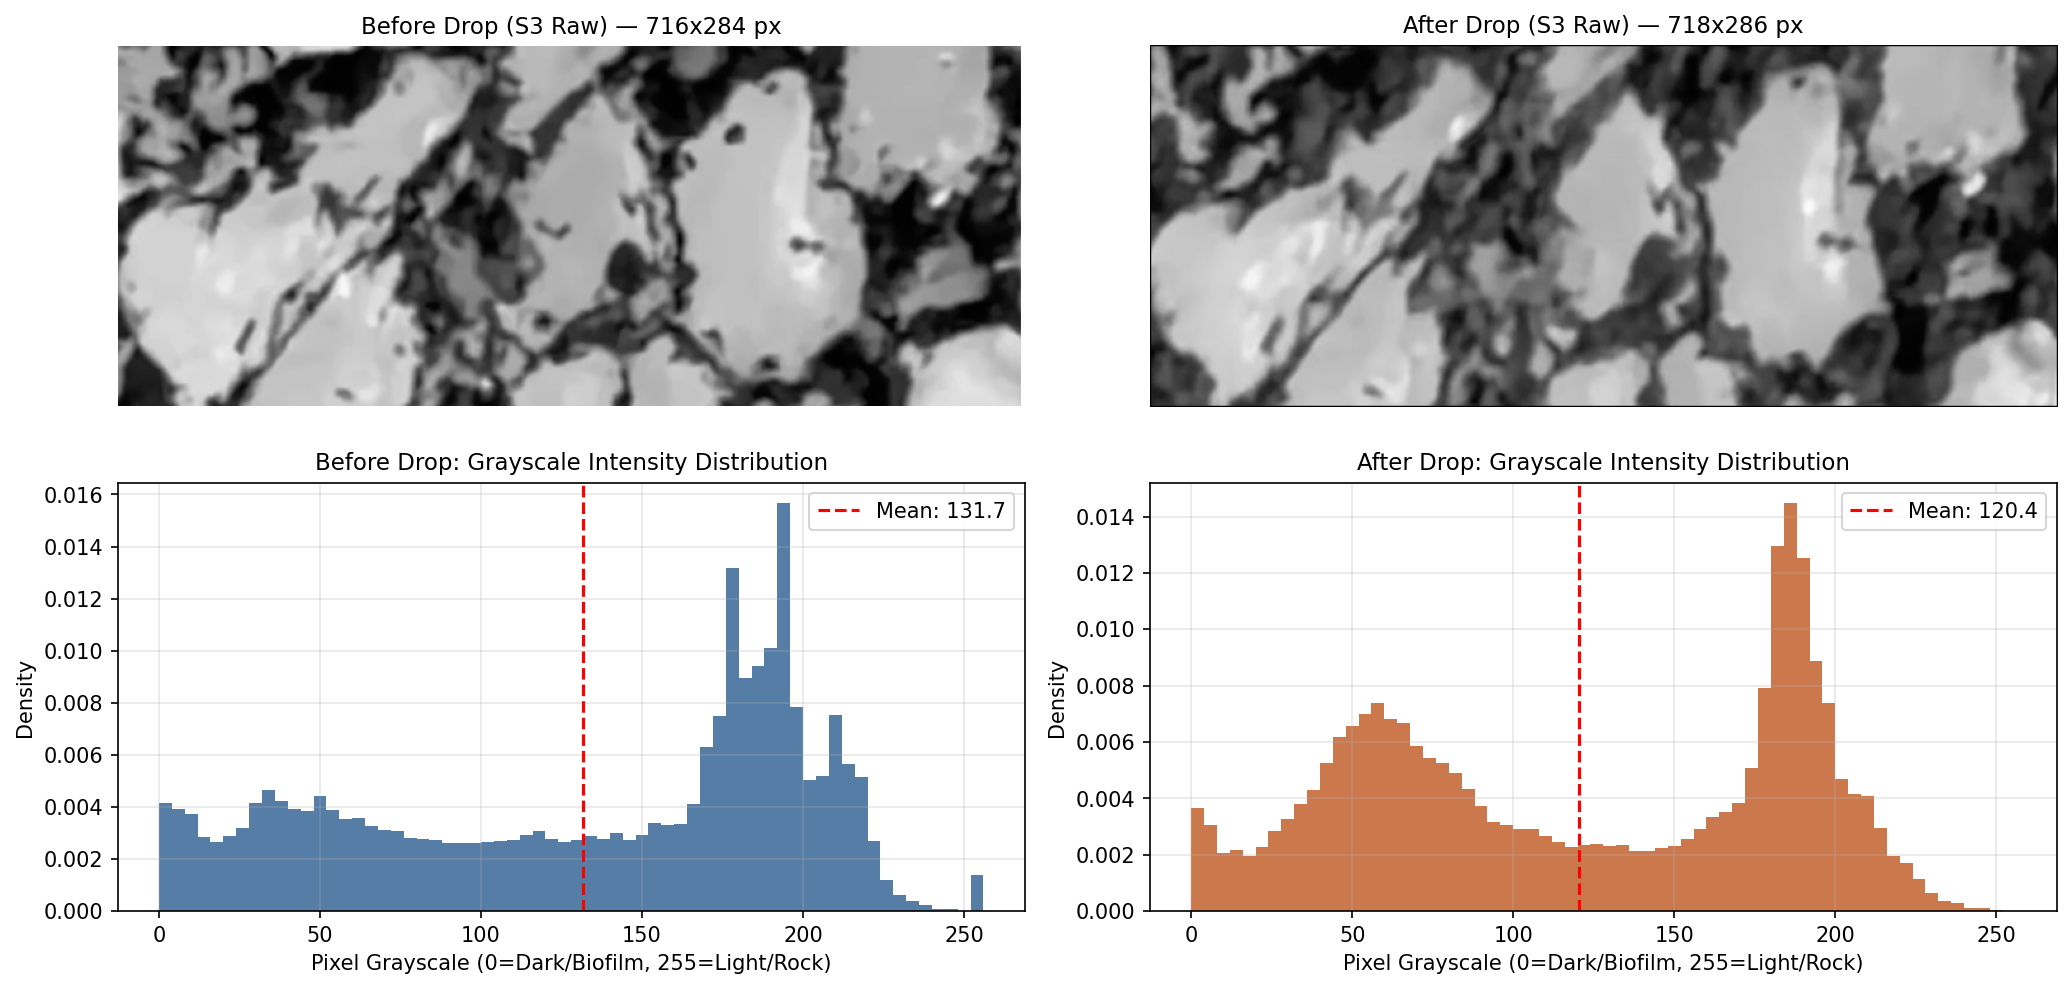

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), gridspec_kw={'height_ratios': [1.2, 1]})

# Raw Images
axes[0, 0].imshow(before_gray, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title(f"Before Drop (S3 Raw) — {before_gray.shape[1]}x{before_gray.shape[0]} px")
axes[0, 0].axis('off')

axes[0, 1].imshow(after_gray, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title(f"After Drop (S3 Raw) — {after_gray.shape[1]}x{after_gray.shape[0]} px")
axes[0, 1].axis('off')

# Intensity Histograms
axes[1, 0].hist(before_gray.ravel(), bins=64, range=(0, 256), color='#2b5c8f', alpha=0.8, density=True)
axes[1, 0].axvline(before_gray.mean(), color='red', linestyle='--', label=f"Mean: {before_gray.mean():.1f}")
axes[1, 0].set_title("Before Drop: Grayscale Intensity Distribution")
axes[1, 0].set_xlabel("Pixel Grayscale (0=Dark/Biofilm, 255=Light/Rock)")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].hist(after_gray.ravel(), bins=64, range=(0, 256), color='#c05621', alpha=0.8, density=True)
axes[1, 1].axvline(after_gray.mean(), color='red', linestyle='--', label=f"Mean: {after_gray.mean():.1f}")
axes[1, 1].set_title("After Drop: Grayscale Intensity Distribution")
axes[1, 1].set_xlabel("Pixel Grayscale (0=Dark/Biofilm, 255=Light/Rock)")
axes[1, 1].set_ylabel("Density")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 3. Computer Vision Image Registration (Alignment)
Because the camera shifted slightly between video captures, pixel coordinates $(x, y)$ in the Before image do not align with $(x, y)$ in the After image.

We apply **SIFT (Scale-Invariant Feature Transform)** keypoint detection, robust matching via **Lowe's ratio test**, and **RANSAC (Random Sample Consensus)** to estimate the exact rigid affine transformation matrix:
$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} s\cos\theta & -s\sin\theta \\ s\sin\theta & s\cos\theta \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix} + \begin{bmatrix} t_x \\ t_y \end{bmatrix}$$

Both images are then mapped onto the exact same common coordinate frame and cropped to eliminate non-overlapping boundary margins.


Detected SIFT Keypoints — Before: 464, After: 407
High-confidence matches (Lowe ratio < 0.75): 44

--- Estimated Camera Motion Parameters ---
Scale Factor:  1.0035 (~100.35% scale retention)
Rotation:      +0.332 degrees
Translation X: -4.78 pixels
Translation Y: +0.59 pixels
RANSAC Inliers: 21 / 44


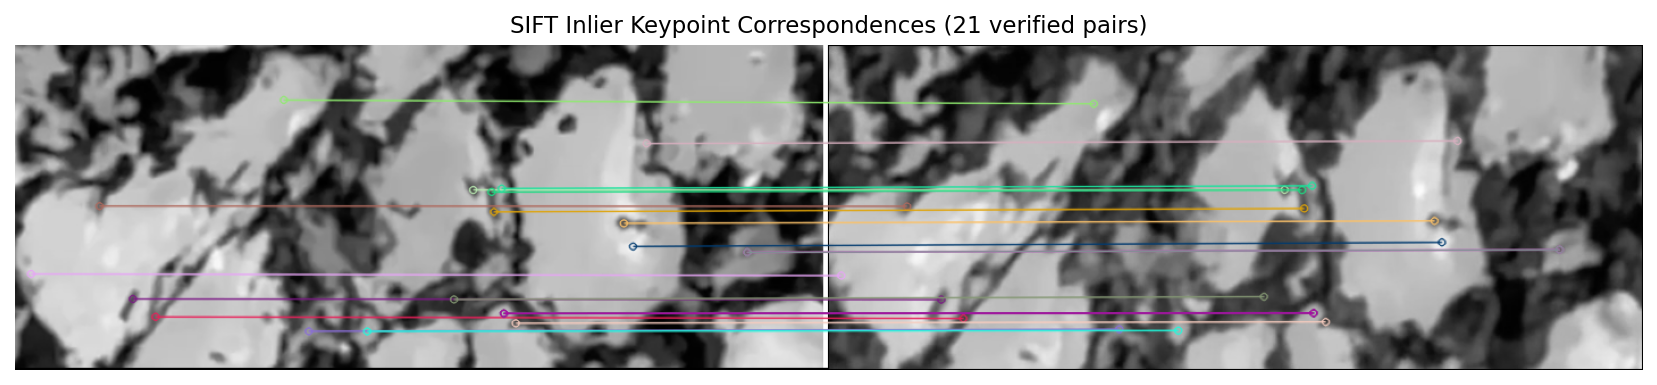

In [4]:
sift = cv2.SIFT_create()
kp_before, des_before = sift.detectAndCompute(before_gray, None)
kp_after, des_after = sift.detectAndCompute(after_gray, None)

print(f"Detected SIFT Keypoints — Before: {len(kp_before)}, After: {len(kp_after)}")

bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
raw_matches = bf.knnMatch(des_before, des_after, k=2)

# Lowe ratio test
good_matches = [m for m, n in raw_matches if m.distance < 0.75 * n.distance]
print(f"High-confidence matches (Lowe ratio < 0.75): {len(good_matches)}")

# Extract coordinates of matched points
src_pts = np.float32([kp_before[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_after[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

# Estimate Affine transformation with RANSAC
M_affine, inlier_mask = cv2.estimateAffinePartial2D(src_pts, dst_pts, method=cv2.RANSAC, ransacReprojThreshold=3.0)

scale = np.sqrt(M_affine[0, 0]**2 + M_affine[0, 1]**2)
rotation_deg = np.arctan2(M_affine[0, 1], M_affine[0, 0]) * 180.0 / np.pi
tx, ty = M_affine[0, 2], M_affine[1, 2]

print("\n--- Estimated Camera Motion Parameters ---")
print(f"Scale Factor:  {scale:.4f} (~{scale*100:.2f}% scale retention)")
print(f"Rotation:      {rotation_deg:+.3f} degrees")
print(f"Translation X: {tx:+.2f} pixels")
print(f"Translation Y: {ty:+.2f} pixels")
print(f"RANSAC Inliers: {np.sum(inlier_mask)} / {len(good_matches)}")

# Visualize Keypoint Matches
match_img = cv2.drawMatches(
    before_gray, kp_before,
    after_gray, kp_after,
    [good_matches[i] for i in range(len(good_matches)) if inlier_mask[i]],
    None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(14, 5))
plt.imshow(match_img)
plt.title(f"SIFT Inlier Keypoint Correspondences ({np.sum(inlier_mask)} verified pairs)")
plt.axis('off')
plt.show()


Registered common area dimensions: 700 x 276 pixels (Total: 193,200 px)


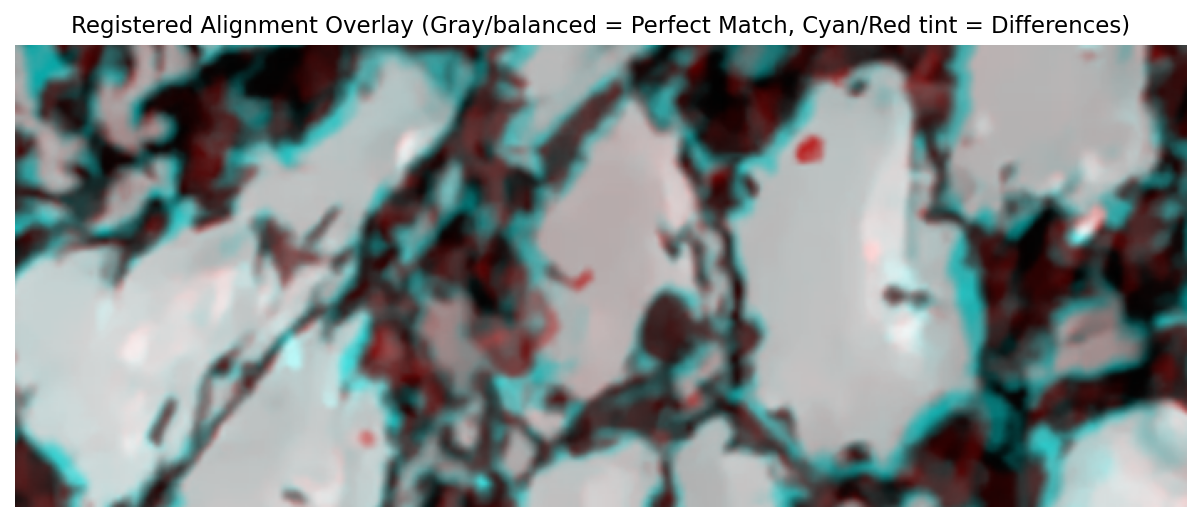

In [5]:
h_after, w_after = after_gray.shape

# Warp Before image to align with After coordinate space
before_aligned = cv2.warpAffine(
    before_gray, M_affine, (w_after, h_after),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=255
)

# Apply safety crop margins to remove boundary interpolation artifacts
pad_y = int(np.ceil(abs(ty))) + 4
pad_x = int(np.ceil(abs(tx))) + 4

before_reg = before_aligned[pad_y:h_after-pad_y, pad_x:w_after-pad_x]
after_reg = after_gray[pad_y:h_after-pad_y, pad_x:w_after-pad_x]

H_reg, W_reg = before_reg.shape
print(f"Registered common area dimensions: {W_reg} x {H_reg} pixels (Total: {H_reg * W_reg:,} px)")

# Check alignment quality using false-color composite
composite = np.zeros((H_reg, W_reg, 3), dtype=np.uint8)
composite[:, :, 0] = after_reg   # Red = After
composite[:, :, 1] = before_reg  # Green = Before
composite[:, :, 2] = before_reg  # Blue = Before (Cyan)

plt.figure(figsize=(12, 4))
plt.imshow(composite)
plt.title("Registered Alignment Overlay (Gray/balanced = Perfect Match, Cyan/Red tint = Differences)")
plt.axis('off')
plt.show()


---
## 4. Biofilm Biomass Segmentation & Quantification
Biofilm corresponds to the **darker regions** (low intensity values), while bare stone appears light.

here we test three complementary segmentation methodologies:
1. **Manual Fiji Reference Threshold:** Replicating the manual Fiji thresholds for Sample 3:
   - Before: $[0, 48]$
   - After: $[0, 81]$
2. **Otsu's Global Threshold:** Maximizes inter-class intensity variance (automated, unbiased).
3. **Triangle Algorithm:** Geometric peak-to-tail thresholding commonly used in fluorescence/biomass imaging.


In [6]:
results_list = []
total_pixels = before_reg.size

# --- 1. Manual Fiji Baseline ---
mask_b_man = (before_reg <= 48)
mask_a_man = (after_reg <= 81)
area_b_man = int(np.sum(mask_b_man))
area_a_man = int(np.sum(mask_a_man))
pct_b_man = (area_b_man / total_pixels) * 100
pct_a_man = (area_a_man / total_pixels) * 100

results_list.append({
    'Method': 'Manual Fiji Reference',
    'Threshold Before': '0 - 48',
    'Threshold After': '0 - 81',
    'Area Before (px)': area_b_man,
    'Coverage Before (%)': pct_b_man,
    'Area After (px)': area_a_man,
    'Coverage After (%)': pct_a_man,
    'Absolute Change (%)': pct_a_man - pct_b_man,
    'Relative Change (%)': ((area_a_man - area_b_man) / area_b_man) * 100
})

# --- 2. Otsu Global Threshold ---
th_b_otsu, cv_mask_b_otsu = cv2.threshold(before_reg, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
th_a_otsu, cv_mask_a_otsu = cv2.threshold(after_reg, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
mask_b_otsu = (cv_mask_b_otsu > 0)
mask_a_otsu = (cv_mask_a_otsu > 0)
area_b_otsu = int(np.sum(mask_b_otsu))
area_a_otsu = int(np.sum(mask_a_otsu))
pct_b_otsu = (area_b_otsu / total_pixels) * 100
pct_a_otsu = (area_a_otsu / total_pixels) * 100

results_list.append({
    'Method': "Otsu's Global",
    'Threshold Before': f"<= {int(th_b_otsu)}",
    'Threshold After': f"<= {int(th_a_otsu)}",
    'Area Before (px)': area_b_otsu,
    'Coverage Before (%)': pct_b_otsu,
    'Area After (px)': area_a_otsu,
    'Coverage After (%)': pct_a_otsu,
    'Absolute Change (%)': pct_a_otsu - pct_b_otsu,
    'Relative Change (%)': ((area_a_otsu - area_b_otsu) / area_b_otsu) * 100
})

# --- 3. Triangle Global Threshold ---
th_b_tri, cv_mask_b_tri = cv2.threshold(before_reg, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_TRIANGLE)
th_a_tri, cv_mask_a_tri = cv2.threshold(after_reg, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_TRIANGLE)
mask_b_tri = (cv_mask_b_tri > 0)
mask_a_tri = (cv_mask_a_tri > 0)
area_b_tri = int(np.sum(mask_b_tri))
area_a_tri = int(np.sum(mask_a_tri))
pct_b_tri = (area_b_tri / total_pixels) * 100
pct_a_tri = (area_a_tri / total_pixels) * 100

results_list.append({
    'Method': 'Triangle Algorithm',
    'Threshold Before': f"<= {int(th_b_tri)}",
    'Threshold After': f"<= {int(th_a_tri)}",
    'Area Before (px)': area_b_tri,
    'Coverage Before (%)': pct_b_tri,
    'Area After (px)': area_a_tri,
    'Coverage After (%)': pct_a_tri,
    'Absolute Change (%)': pct_a_tri - pct_b_tri,
    'Relative Change (%)': ((area_a_tri - area_b_tri) / area_b_tri) * 100
})

df_methods = pd.DataFrame(results_list)
print(df_methods[['Method', 'Threshold Before', 'Threshold After', 'Coverage Before (%)', 'Coverage After (%)', 'Absolute Change (%)', 'Relative Change (%)']].to_string(index=False))


               Method Threshold Before Threshold After  Coverage Before (%)  Coverage After (%)  Absolute Change (%)  Relative Change (%)
Manual Fiji Reference           0 - 48          0 - 81            17.663561           36.142340            18.478778           104.615249
        Otsu's Global           <= 118          <= 121            39.077640           48.910455             9.832816            25.162256
   Triangle Algorithm           <= 162          <= 166            51.974638           60.490683             8.516046            16.385002


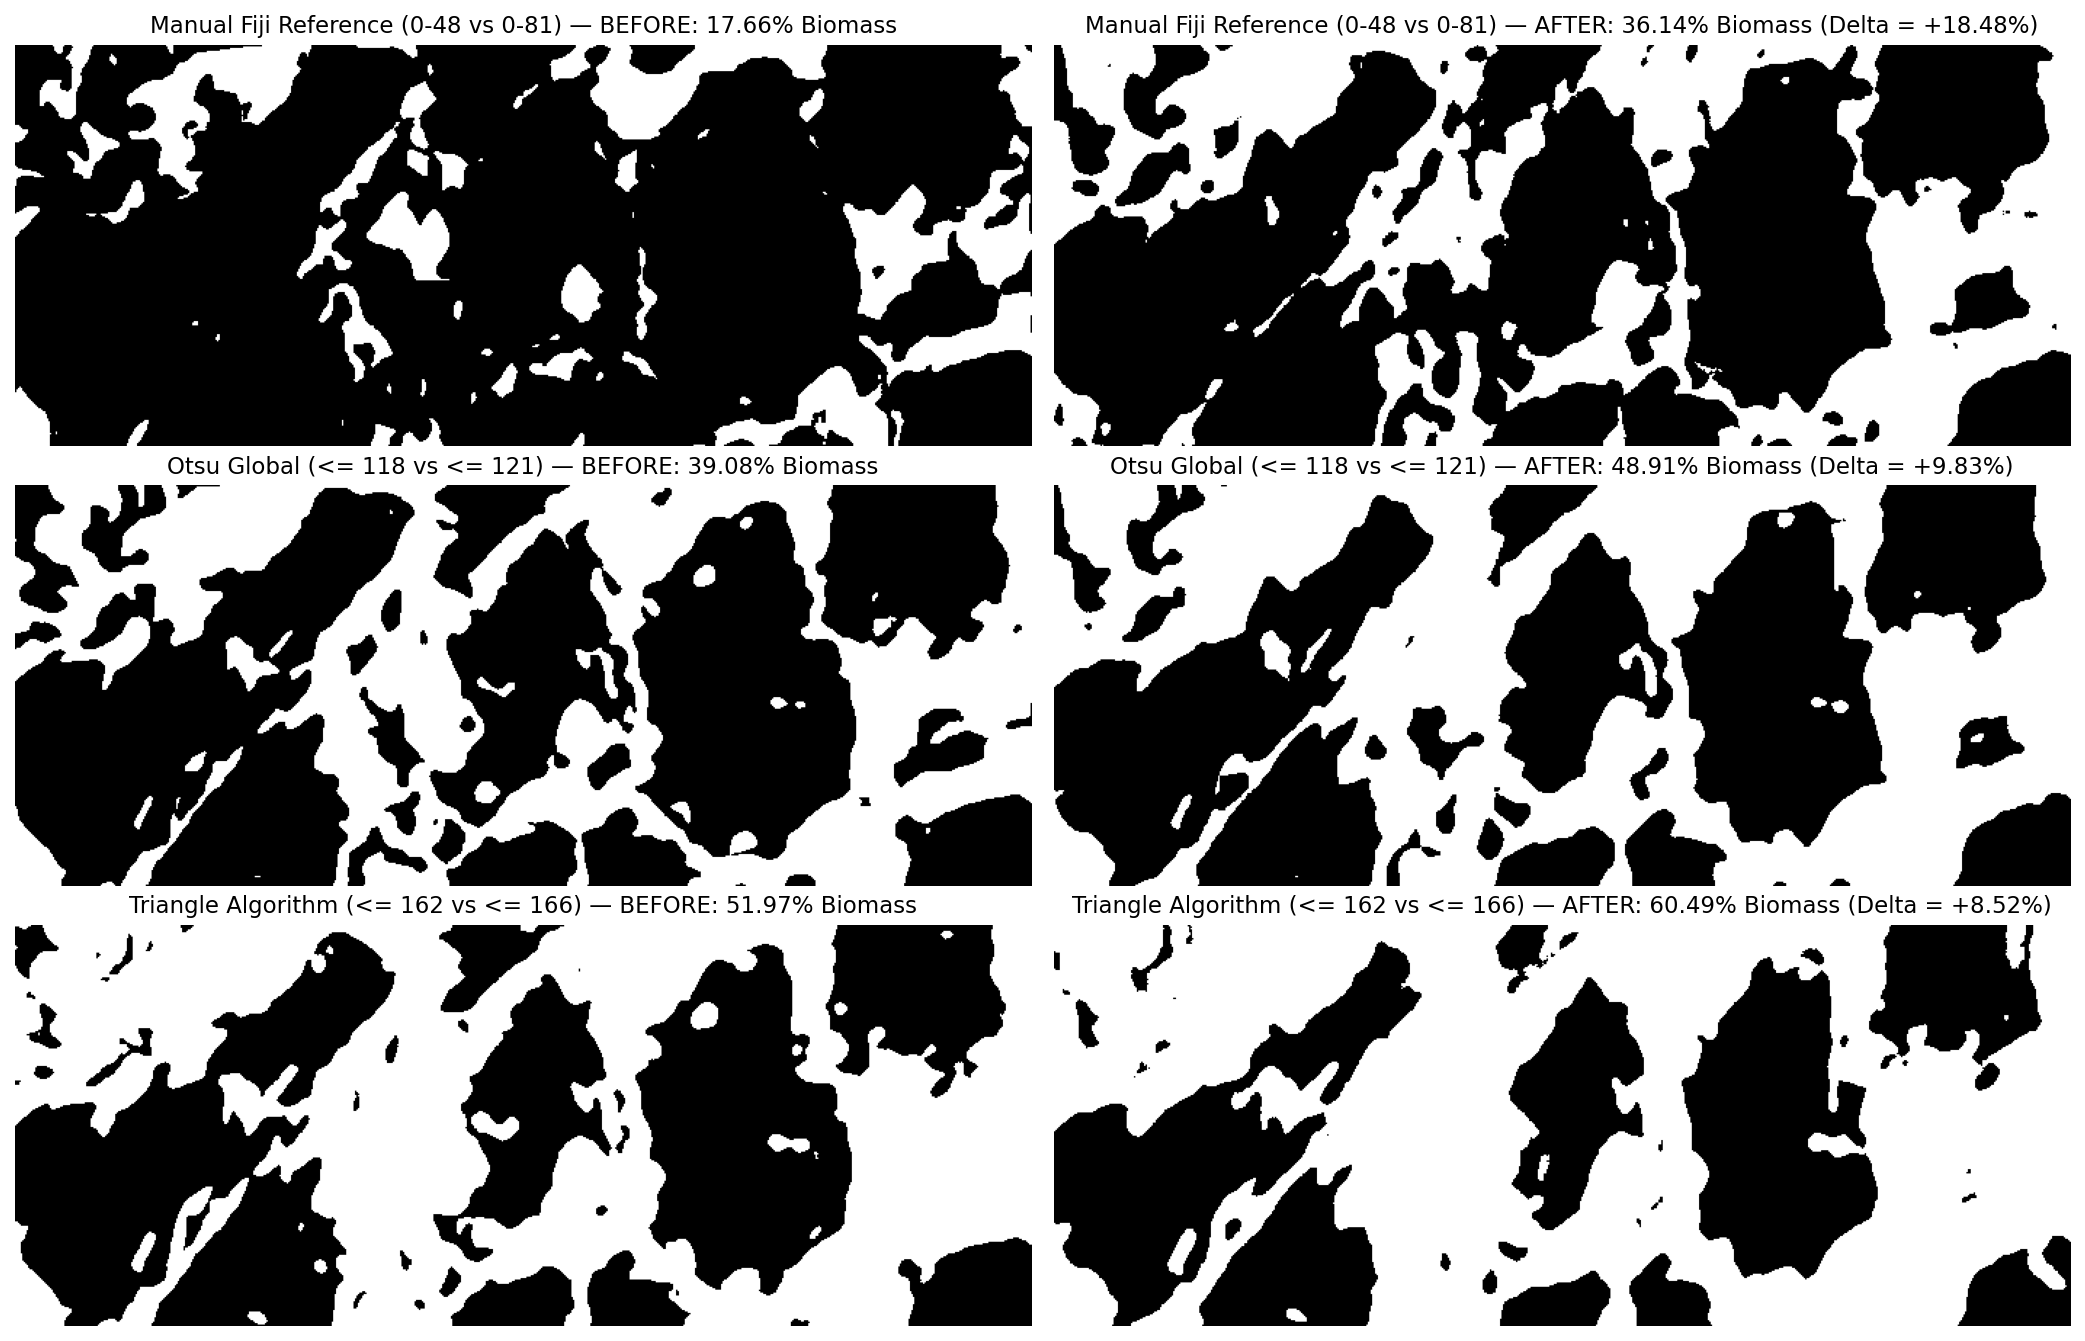

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9))

methods = [
    ('Manual Fiji Reference (0-48 vs 0-81)', mask_b_man, mask_a_man, pct_b_man, pct_a_man),
    (f"Otsu Global (<= {int(th_b_otsu)} vs <= {int(th_a_otsu)})", mask_b_otsu, mask_a_otsu, pct_b_otsu, pct_a_otsu),
    (f"Triangle Algorithm (<= {int(th_b_tri)} vs <= {int(th_a_tri)})", mask_b_tri, mask_a_tri, pct_b_tri, pct_a_tri),
]

for idx, (title, mb, ma, pb, pa) in enumerate(methods):
    axes[idx, 0].imshow(mb, cmap='gray')
    axes[idx, 0].set_title(f"{title} — BEFORE: {pb:.2f}% Biomass")
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(ma, cmap='gray')
    axes[idx, 1].set_title(f"{title} — AFTER: {pa:.2f}% Biomass (Delta = +{pa-pb:.2f}%)")
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()


---
## 5. Sub-Region (ROI) Analysis: Whole vs. Divided Image
A key research question is whether **whole image** measurements agree with an **8-region divided sub-image analysis**.

We divide the registered image into an identical $4 \times 2$ grid (8 equal rectangular ROIs), mirroring Fiji's ROI Manager, and compute:
- Mean intensity & standard deviation
- Biofilm area ($px^2$) and coverage percentage (%)
- Local delta change (%) per region


In [8]:
rows, cols = 2, 4
tile_h = H_reg // rows
tile_w = W_reg // cols

roi_records = []

for r in range(rows):
    for c in range(cols):
        roi_num = r * cols + c + 1
        y1, y2 = r * tile_h, (r + 1) * tile_h
        x1, x2 = c * tile_w, (c + 1) * tile_w
        
        tile_b = before_reg[y1:y2, x1:x2]
        tile_a = after_reg[y1:y2, x1:x2]
        
        # Sub-region binary masks (Manual threshold reference)
        sub_mb = (tile_b <= 48)
        sub_ma = (tile_a <= 81)
        
        area_b = int(np.sum(sub_mb))
        area_a = int(np.sum(sub_ma))
        tile_px = tile_b.size
        
        cov_b = (area_b / tile_px) * 100
        cov_a = (area_a / tile_px) * 100
        delta = cov_a - cov_b
        
        roi_records.append({
            'ROI': f"ROI {roi_num}",
            'Row': r + 1,
            'Col': c + 1,
            'Mean Before': tile_b.mean(),
            'Std Before': tile_b.std(),
            'Coverage Before (%)': cov_b,
            'Mean After': tile_a.mean(),
            'Std After': tile_a.std(),
            'Coverage After (%)': cov_a,
            'Delta Change (%)': delta
        })

df_rois = pd.DataFrame(roi_records)
print(df_rois[['ROI', 'Coverage Before (%)', 'Coverage After (%)', 'Delta Change (%)', 'Mean Before', 'Mean After']].to_string(index=False))

# Print comparison of Whole Image vs. Average of Sub-regions
avg_cov_b = df_rois['Coverage Before (%)'].mean()
avg_cov_a = df_rois['Coverage After (%)'].mean()
print("\n--- Consistency Comparison: Whole Image vs Divided ROIs ---")
print(f"Whole Image:   Before = {pct_b_man:.2f}% | After = {pct_a_man:.2f}% | Delta = +{pct_a_man - pct_b_man:.2f}%")
print(f"ROIs Average:  Before = {avg_cov_b:.2f}% | After = {avg_cov_a:.2f}% | Delta = +{avg_cov_a - avg_cov_b:.2f}%")
print(f"Discrepancy:   Before = {abs(pct_b_man - avg_cov_b):.2f}% | After = {abs(pct_a_man - avg_cov_a):.2f}%")


  ROI  Coverage Before (%)  Coverage After (%)  Delta Change (%)  Mean Before  Mean After
ROI 1            26.004141           53.805383         27.801242   104.432215   90.983727
ROI 2            18.244306           42.633540         24.389234   122.043727  107.874783
ROI 3            19.329193           32.215321         12.886128   135.508737  132.333126
ROI 4            20.877847           36.012422         15.134576   126.573499  122.173375
ROI 5             3.685300            7.213251          3.527950   189.169358  179.685217
ROI 6            11.134576           29.904762         18.770186   125.871636  120.221781
ROI 7            10.041408           28.426501         18.385093   143.477516  135.914741
ROI 8            31.991718           58.927536         26.935818   109.072795   92.978841

--- Consistency Comparison: Whole Image vs Divided ROIs ---
Whole Image:   Before = 17.66% | After = 36.14% | Delta = +18.48%
ROIs Average:  Before = 17.66% | After = 36.14% | Delta = +18.4

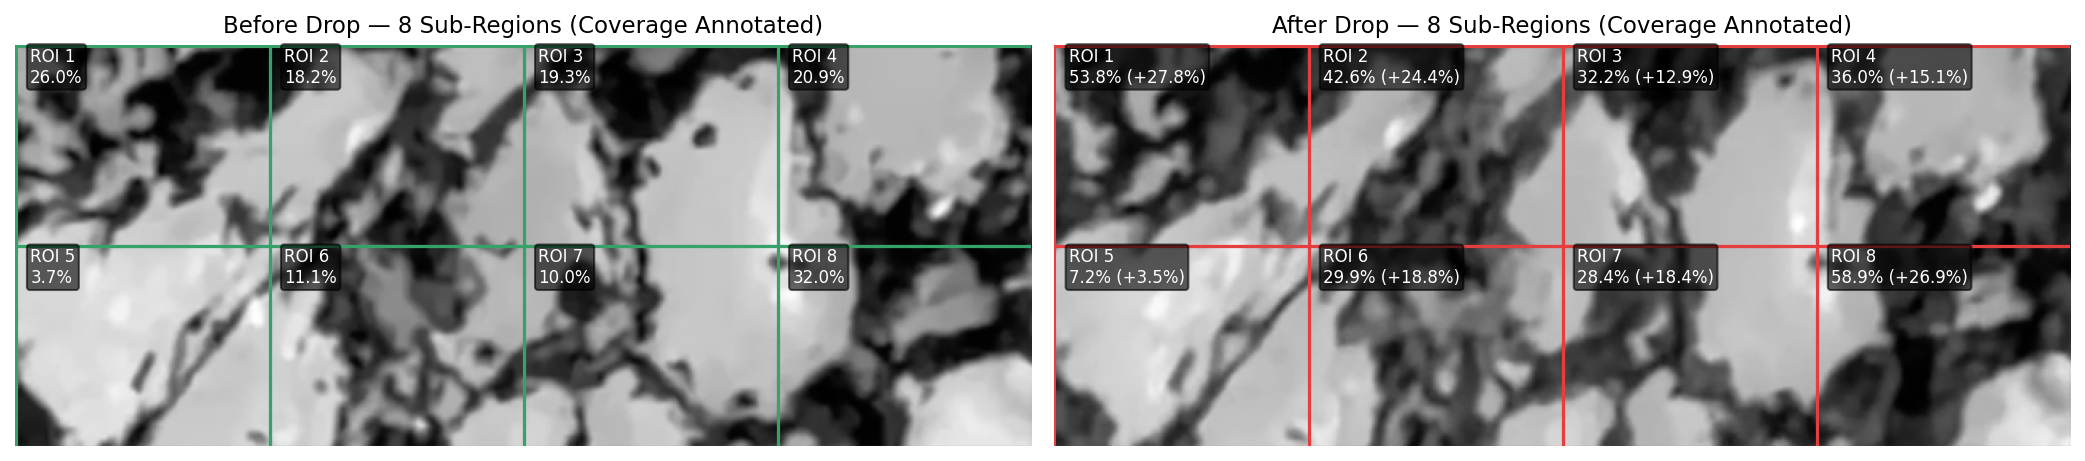

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Before with ROI boxes
axes[0].imshow(before_reg, cmap='gray')
axes[0].set_title("Before Drop — 8 Sub-Regions (Coverage Annotated)")
for r in range(rows):
    for c in range(cols):
        roi_num = r * cols + c + 1
        y1, y2 = r * tile_h, (r + 1) * tile_h
        x1, x2 = c * tile_w, (c + 1) * tile_w
        rect = patches.Rectangle((x1, y1), tile_w, tile_h, linewidth=1.5, edgecolor='#38a169', facecolor='none')
        axes[0].add_patch(rect)
        cov = df_rois.loc[roi_num - 1, 'Coverage Before (%)']
        axes[0].text(x1 + 10, y1 + 25, f"ROI {roi_num}\n{cov:.1f}%", color='white',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6), fontsize=8)
axes[0].axis('off')

# Plot After with ROI boxes
axes[1].imshow(after_reg, cmap='gray')
axes[1].set_title("After Drop — 8 Sub-Regions (Coverage Annotated)")
for r in range(rows):
    for c in range(cols):
        roi_num = r * cols + c + 1
        y1, y2 = r * tile_h, (r + 1) * tile_h
        x1, x2 = c * tile_w, (c + 1) * tile_w
        rect = patches.Rectangle((x1, y1), tile_w, tile_h, linewidth=1.5, edgecolor='#e53e3e', facecolor='none')
        axes[1].add_patch(rect)
        cov = df_rois.loc[roi_num - 1, 'Coverage After (%)']
        delta = df_rois.loc[roi_num - 1, 'Delta Change (%)']
        axes[1].text(x1 + 10, y1 + 25, f"ROI {roi_num}\n{cov:.1f}% (+{delta:.1f}%)", color='white',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6), fontsize=8)
axes[1].axis('off')

plt.tight_layout()
plt.show()


---
## 6. Spatial Biomass Dynamics & Difference Mapping
To provide clear scientific visualization for the project, we construct a 4-state spatial category map:
1. **Unchanged Bare Rock (Light Gray):** Clean substrate before and after.
2. **Persistent Biofilm (Dark Slate Blue):** Biomass present both before and after the drop.
3. **Newly Expanded / Darkened Biofilm (Crimson Red):** Regions where biofilm expanded or optical density increased after droplet exposure.
4. **Apparent Reduction (Amber / Rare):** Regions that lightened.


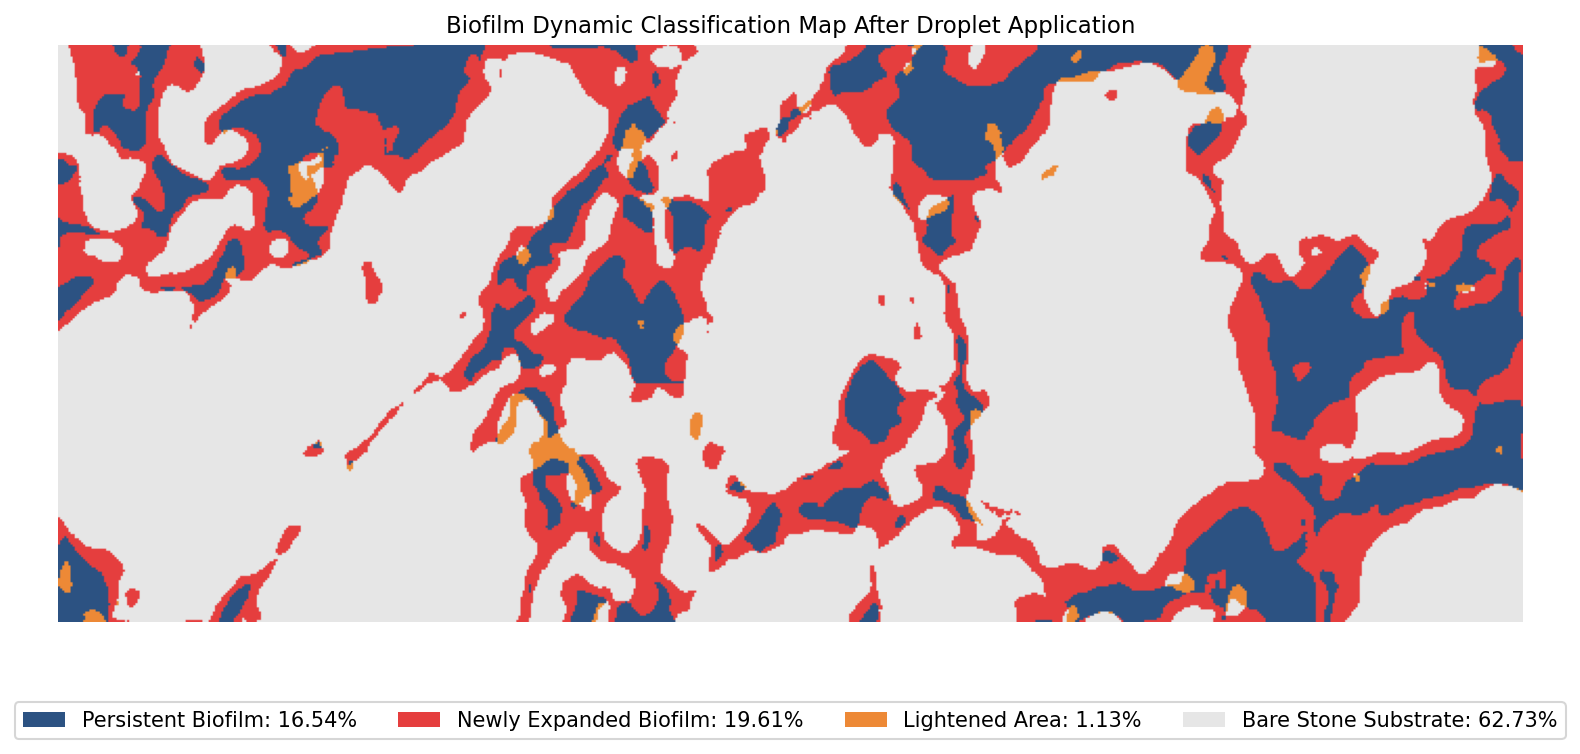

In [10]:
persistent_biofilm = mask_b_man & mask_a_man
expanded_biofilm   = (~mask_b_man) & mask_a_man
lightened_region   = mask_b_man & (~mask_a_man)
unchanged_rock     = (~mask_b_man) & (~mask_a_man)

pct_persistent = (np.sum(persistent_biofilm) / total_pixels) * 100
pct_expanded   = (np.sum(expanded_biofilm) / total_pixels) * 100
pct_lightened  = (np.sum(lightened_region) / total_pixels) * 100
pct_rock       = (np.sum(unchanged_rock) / total_pixels) * 100

# Color representation
diff_rgb = np.zeros((H_reg, W_reg, 3), dtype=np.uint8)
diff_rgb[unchanged_rock]     = [230, 230, 230]  # Light gray
diff_rgb[persistent_biofilm] = [44, 82, 130]    # Blue
diff_rgb[expanded_biofilm]   = [229, 62, 62]    # Red
diff_rgb[lightened_region]   = [237, 137, 54]   # Orange/Amber

plt.figure(figsize=(14, 5))
plt.imshow(diff_rgb)
plt.title("Biofilm Dynamic Classification Map After Droplet Application")
plt.axis('off')

# Custom Legend
legend_patches = [
    patches.Patch(facecolor='#2c5282', label=f'Persistent Biofilm: {pct_persistent:.2f}%'),
    patches.Patch(facecolor='#e53e3e', label=f'Newly Expanded Biofilm: {pct_expanded:.2f}%'),
    patches.Patch(facecolor='#ed8936', label=f'Lightened Area: {pct_lightened:.2f}%'),
    patches.Patch(facecolor='#e6e6e6', label=f'Bare Stone Substrate: {pct_rock:.2f}%')
]
plt.legend(handles=legend_patches, loc='lower center', bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=True)
plt.show()


---
## 7. Results Export for the project / Paper
We export all quantitative tables to CSV format for seamless inclusion into LaTeX, Word, or thesis appendices etc.


In [11]:
# Export ROI table
roi_csv_path = 'biomass_roi_results_s3.csv'
df_rois.to_csv(roi_csv_path, index=False)
print(f"Saved ROI results to: {roi_csv_path}")

# Export Global Methods table
methods_csv_path = 'biomass_methods_comparison_s3.csv'
df_methods.to_csv(methods_csv_path, index=False)
print(f"Saved Global Methods comparison to: {methods_csv_path}")

print("\n--- SUMMARY FINDINGS ---")
print(f"1. Alignment: SIFT+RANSAC corrected camera shift (dx={tx:.2f}px, dy={ty:.2f}px, rot={rotation_deg:.2f}°).")
print(f"2. Manual Fiji Reproduction: Biofilm coverage grew from {pct_b_man:.2f}% to {pct_a_man:.2f}% (+Delta = {pct_a_man-pct_b_man:.2f}%).")
print(f"3. Automated Otsu: Biofilm grew from {pct_b_otsu:.2f}% to {pct_a_otsu:.2f}% (+Delta = {pct_a_otsu-pct_b_otsu:.2f}%).")
print(f"4. Sub-Region Consistency: Average of 8 sub-regions yielded {avg_cov_a - avg_cov_b:+.2f}% change, within {abs((pct_a_man-pct_b_man)-(avg_cov_a-avg_cov_b)):.2f}% of whole-image estimate.")
print(f"5. Net Expansion: {pct_expanded:.2f}% of the rock surface transformed from clean stone into newly covered biofilm.")


Saved ROI results to: biomass_roi_results_s3.csv
Saved Global Methods comparison to: biomass_methods_comparison_s3.csv

--- SUMMARY FINDINGS ---
1. Alignment: SIFT+RANSAC corrected camera shift (dx=-4.78px, dy=0.59px, rot=0.33°).
2. Manual Fiji Reproduction: Biofilm coverage grew from 17.66% to 36.14% (+Delta = 18.48%).
3. Automated Otsu: Biofilm grew from 39.08% to 48.91% (+Delta = 9.83%).
4. Sub-Region Consistency: Average of 8 sub-regions yielded +18.48% change, within 0.00% of whole-image estimate.
5. Net Expansion: 19.61% of the rock surface transformed from clean stone into newly covered biofilm.
